# Pima Indians Diabetes — SVM, preparação de dados e MLflow

**Objetivo:** aplicar **máquinas de vetores de suporte** (SVM) à predição de diabetes na base *Pima Indians Diabetes*, **justificando cada transformação de preparação dos dados** e demonstrando pelas métricas o efeito de cada uma. Todos os experimentos são registrados no **MLflow**.

**Problema:** classificação binária. A coluna `Outcome` é o alvo — **1 = diagnóstico de diabetes**, **0 = sem diagnóstico**. A base tem 768 pacientes (todas mulheres de herança Pima, com 21 anos ou mais) e 8 atributos clínicos.

**Erro de maior custo:** o **falso negativo** — uma paciente diabética classificada como saudável fica sem acompanhamento. Por isso a avaliação privilegia a revocação e o F1 da classe 1, e as contagens de falsos negativos são reportadas explicitamente.

**O que é comparado (tudo registrado no MLflow):**
- **Preparação:** tratamento dos zeros impossíveis, estratégia de imputação (mediana, média, KNN, descarte) e escala (nenhuma, padronização, min-max).
- **Modelo:** os quatro kernels do SVM (linear, RBF, polinomial, sigmoide) e seus hiperparâmetros `C`, `gamma`, `degree` e `class_weight`.
- **Protocolo de validação:** proporção treino/teste, variabilidade entre partições, estratificação e esquema de validação cruzada.
- **Engenharia de atributos:** cinco razões clínicas, medidas por quatro métodos complementares.

> **Como executar:** ajuste `MODO` na primeira célula (`'completa'`, `'rapida'` ou `'smoke'`) e rode todas as células.

## Configuração e parâmetros do experimento

In [1]:
import os, json, time, shutil, zipfile, warnings
from datetime import datetime
from pathlib import Path

os.environ.setdefault('PYTHONWARNINGS', 'ignore')   # propaga aos workers do n_jobs=-1
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, ParameterGrid)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix)

import mlflow
import mlflow.sklearn

SEED = 42
np.random.seed(SEED)

# ---------------------------------------------------------------------------
# Parametros globais do experimento (edite aqui)
# ---------------------------------------------------------------------------
# MODO controla o tamanho da grade e o numero de repeticoes:
#   'completa' -> grade cheia (136 combinacoes) e todas as repeticoes
#   'rapida'   -> grade reduzida, menos repeticoes (primeira passada)
#   'smoke'    -> grade minima, apenas para testar o fluxo
MODO = os.environ.get('PIMA_MODO', 'completa')

COLUNAS = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
           'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
ALVO = 'Outcome'
PREDITORES = COLUNAS[:-1]

# zero fisiologicamente impossivel -> ausente.
# 'Pregnancies' NAO entra: zero gestacoes e um valor legitimo (mulher nulipara).
ZERO_INVALIDO = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

IMPUTACOES = ['mediana', 'media', 'knn', 'descarte']
ESCALAS = ['nenhuma', 'padrao', 'minmax']

# limite de iteracoes do SVM: garante termino mesmo em combinacoes que nao
# convergem (kernel polinomial/sigmoide com C alto sobre dados nao padronizados)
MAX_ITER = 100_000

print('scikit-learn', sklearn.__version__, '| mlflow', mlflow.__version__)
print('MODO:', MODO)

scikit-learn 1.9.1 | mlflow 3.18.0
MODO: completa


## Localização do projeto e MLflow

Mesma convenção dos notebooks anteriores: a raiz é a pasta que contém `bases/`, o MLflow grava no `mlflow.db` compartilhado e os artefatos vão para `docs/svm`.

In [2]:
def localiza_raiz(inicio=None):
    """Sobe a partir do diretorio atual ate encontrar bases/pima-indians-diabetes.csv."""
    env = os.environ.get('PIMA_RAIZ')
    if env:
        return Path(env).resolve()
    atual = Path(inicio or Path.cwd()).resolve()
    for pasta in [atual, *atual.parents]:
        if (pasta / 'bases' / 'pima-indians-diabetes.csv').exists():
            return pasta
    raise FileNotFoundError('Nao encontrei bases/pima-indians-diabetes.csv a partir de ' + str(atual))


RAIZ = localiza_raiz()
CSV = RAIZ / 'bases' / 'pima-indians-diabetes.csv'

# tudo que for gerado fica em docs/svm
PASTA_DOCS = RAIZ / 'docs' / 'svm'
PASTA_EXECUCAO = PASTA_DOCS / 'resultados' / f'execucao_{datetime.now():%Y%m%d_%H%M%S}'
PASTA_FIGURAS = PASTA_DOCS / 'figuras'
PASTA_EXECUCAO.mkdir(parents=True, exist_ok=True)
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

MLFLOW_DB = (RAIZ / 'mlflow.db').resolve()
mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DB}')
EXPERIMENTO = 'pima_svm'
mlflow.set_experiment(EXPERIMENTO)


def salva_fig(fig, nome, dpi=150):
    """Salva a figura na pasta da execucao e copia para docs/svm/figuras."""
    destino = PASTA_EXECUCAO / nome
    fig.savefig(destino, dpi=dpi, bbox_inches='tight')
    shutil.copy(destino, PASTA_FIGURAS / nome)
    return destino


print('Base:', CSV)
print('Tracking URI:', mlflow.get_tracking_uri())
print('Experimento:', EXPERIMENTO)
print('Pasta da execucao:', PASTA_EXECUCAO)

Base: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/bases/pima-indians-diabetes.csv
Tracking URI: sqlite:////Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/mlflow.db
Experimento: pima_svm
Pasta da execucao: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/docs/svm/resultados/execucao_20261116_100225


## Entendimento da base

**Atenção ao cabeçalho.** O arquivo `pima-indians-diabetes.csv` **não tem linha de cabeçalho**: a primeira linha já é uma paciente. Lido com o padrão do pandas, perderia-se um registro e as colunas receberiam como nome os valores dessa paciente. Os nomes são, por isso, atribuídos explicitamente.

As oito variáveis preditoras são clínicas: número de gestações, glicose plasmática no teste oral de tolerância, pressão diastólica, prega cutânea do tríceps, insulina sérica em 2 h, índice de massa corporal, um escore de histórico familiar de diabetes e a idade.

Formato: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Valores ausentes declarados (NaN): 0
Linhas duplicadas: 0

Distribuicao do alvo (Outcome):
Outcome
0 (sem diabetes)    500
1 (com diabetes)    268
Proporcao da classe 1: 0.3490

=== Zeros por coluna ===


,Variavel,Zeros,Percentual,Zero e plausivel?
0,Pregnancies,111,14.5,sim
1,Glucose,5,0.7,nao
2,BloodPressure,35,4.6,nao
3,SkinThickness,227,29.6,nao
4,Insulin,374,48.7,nao
5,BMI,11,1.4,nao
6,DiabetesPedigreeFunction,0,0.0,sim
7,Age,0,0.0,sim



=== Estatisticas descritivas ===


,mean,std,min,50%,max
Pregnancies,3.85,3.37,0.00,3.00,17.00
Glucose,120.89,31.97,0.00,117.00,199.00
BloodPressure,69.11,19.36,0.00,72.00,122.00
SkinThickness,20.54,15.95,0.00,23.00,99.00
Insulin,79.80,115.24,0.00,30.50,846.00
BMI,31.99,7.88,0.00,32.00,67.10
DiabetesPedigreeFunction,0.47,0.33,0.08,0.37,2.42
Age,33.24,11.76,21.00,29.00,81.00



=== Correlacao de Spearman com o alvo (zeros impossiveis ignorados) ===


,correlacao
Glucose,0.483
Insulin,0.377
BMI,0.309
Age,0.309
SkinThickness,0.265
Pregnancies,0.199
BloodPressure,0.177
DiabetesPedigreeFunction,0.175


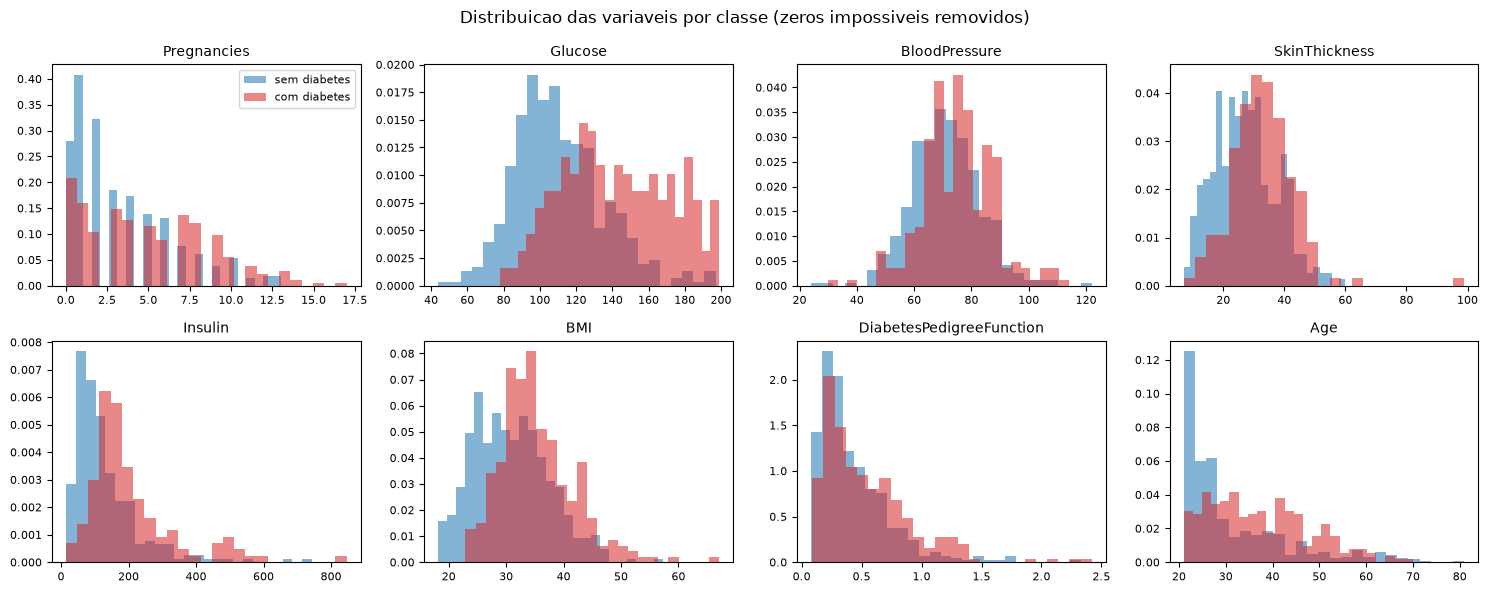

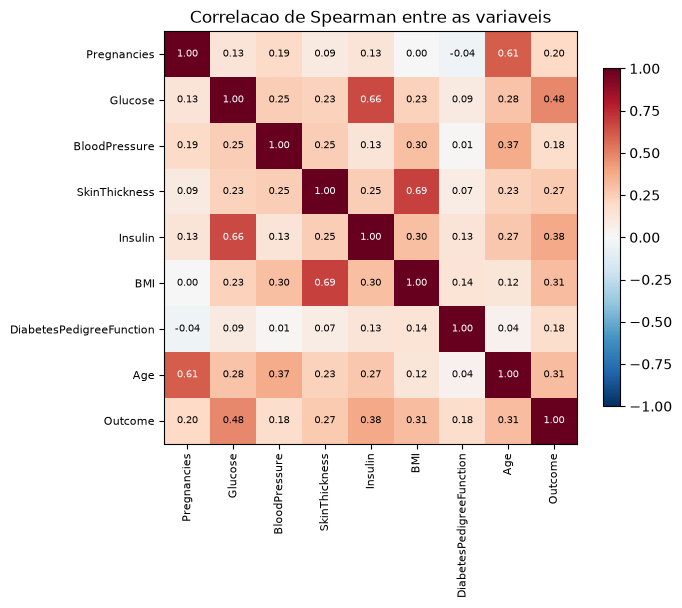

In [3]:
# O arquivo NAO tem cabecalho: a primeira linha ja e uma paciente.
# Ler com o padrao do pandas perderia um registro e nomearia as colunas
# com os valores dessa paciente. Por isso os nomes sao atribuidos aqui.
bruto = pd.read_csv(CSV, header=None, names=COLUNAS)
print('Formato:', bruto.shape)
display(bruto.head())

print('\nValores ausentes declarados (NaN):', int(bruto.isna().sum().sum()))
print('Linhas duplicadas:', int(bruto.duplicated().sum()))
print('\nDistribuicao do alvo (Outcome):')
print(bruto[ALVO].value_counts().rename({0: '0 (sem diabetes)', 1: '1 (com diabetes)'}).to_string())
print('Proporcao da classe 1: %.4f' % bruto[ALVO].mean())

print('\n=== Zeros por coluna ===')
linhas_zero = []
for c in PREDITORES:
    n = int((bruto[c] == 0).sum())
    linhas_zero.append({'Variavel': c, 'Zeros': n, 'Percentual': round(100 * n / len(bruto), 1),
                        'Zero e plausivel?': 'sim' if c not in ZERO_INVALIDO else 'nao'})
tabela_zeros = pd.DataFrame(linhas_zero)
tabela_zeros.to_csv(PASTA_EXECUCAO / 'zeros_por_coluna.csv', index=False)
display(tabela_zeros)

print('\n=== Estatisticas descritivas ===')
display(bruto[PREDITORES].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))

# correlacao de Spearman com o alvo, ja tratando os zeros impossiveis como ausentes
tmp = bruto.copy()
for c in ZERO_INVALIDO:
    tmp[c] = tmp[c].replace(0, np.nan)
corr = tmp.corr(method='spearman')[ALVO].drop(ALVO).sort_values(ascending=False)
print('\n=== Correlacao de Spearman com o alvo (zeros impossiveis ignorados) ===')
display(corr.to_frame('correlacao').round(3))

# Figura 1 — distribuicao das variaveis por classe
fig, eixos = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(eixos.ravel(), PREDITORES):
    for classe, cor, rot in [(0, 'tab:blue', 'sem diabetes'), (1, 'tab:red', 'com diabetes')]:
        ax.hist(tmp.loc[tmp[ALVO] == classe, c].dropna(), bins=25, alpha=0.55,
                color=cor, label=rot, density=True)
    ax.set_title(c, fontsize=10)
    ax.tick_params(labelsize=8)
eixos.ravel()[0].legend(fontsize=8)
fig.suptitle('Distribuicao das variaveis por classe (zeros impossiveis removidos)', fontsize=12)
fig.tight_layout()
salva_fig(fig, 'distribuicao_por_classe.png')
plt.show()

# Figura 2 — mapa de correlacao
fig, ax = plt.subplots(figsize=(7, 6))
m = tmp.corr(method='spearman')
im = ax.imshow(m, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(m))); ax.set_xticklabels(m.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(m))); ax.set_yticklabels(m.columns, fontsize=8)
for i in range(len(m)):
    for j in range(len(m)):
        ax.text(j, i, f'{m.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(m.iloc[i, j]) > 0.5 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Correlacao de Spearman entre as variaveis')
fig.tight_layout()
salva_fig(fig, 'mapa_correlacao.png')
plt.show()

## Limpeza: os zeros fisiologicamente impossíveis

A base não traz nenhum `NaN`, mas isso é enganoso: os valores ausentes foram **codificados como zero**. Glicose, pressão, prega cutânea, insulina e IMC iguais a zero são impossíveis em uma paciente viva e representam medições não realizadas.

A distinção que importa é que **`Pregnancies` igual a zero é legítimo** — corresponde a uma mulher nulípara, e tratá-lo como ausente introduziria erro em 111 registros. Por isso a conversão é seletiva.

In [4]:
def limpa(df_bruto, registra=True):
    """Marca como ausentes os zeros fisiologicamente impossiveis.

    'Pregnancies' fica de fora de proposito: zero gestacoes e um valor real
    (mulher nulipara), e trata-lo como ausente introduziria erro.
    """
    d = df_bruto.copy()
    log = {}
    for c in ZERO_INVALIDO:
        n = int((d[c] == 0).sum())
        d[c] = d[c].replace(0, np.nan)
        log[c] = n
    log['linhas_com_ausente'] = int(d[PREDITORES].isna().any(axis=1).sum())
    log['linhas_completas'] = int((~d[PREDITORES].isna().any(axis=1)).sum())
    if registra:
        print('Zeros convertidos em ausentes:')
        for c in ZERO_INVALIDO:
            print(f'  {c:16s} {log[c]:4d} ({100*log[c]/len(d):4.1f}%)')
        print(f"\nLinhas com ao menos um ausente: {log['linhas_com_ausente']} "
              f"({100*log['linhas_com_ausente']/len(d):.1f}%)")
        print(f"Linhas completas: {log['linhas_completas']}")
    return d, log


limpo, log_limpeza = limpa(bruto)
pd.DataFrame([log_limpeza]).to_csv(PASTA_EXECUCAO / 'limpeza.csv', index=False)

print('\nObservacao: descartar as linhas incompletas deixaria apenas '
      f"{log_limpeza['linhas_completas']} de {len(bruto)} registros "
      f'({100*log_limpeza["linhas_completas"]/len(bruto):.0f}%). '
      'Por isso a estrategia de imputacao e comparada experimentalmente.')

Zeros convertidos em ausentes:
  Glucose             5 ( 0.7%)
  BloodPressure      35 ( 4.6%)
  SkinThickness     227 (29.6%)
  Insulin           374 (48.7%)
  BMI                11 ( 1.4%)

Linhas com ao menos um ausente: 376 (49.0%)
Linhas completas: 392

Observacao: descartar as linhas incompletas deixaria apenas 392 de 768 registros (51%). Por isso a estrategia de imputacao e comparada experimentalmente.


## Fluxo de processamento, engenharia de atributos e métricas

O fluxo é **imputação → engenharia → escala → SVM**, todos ajustados apenas na partição de treino de cada iteração da validação cruzada, o que elimina vazamento de informação.

As cinco variáveis derivadas são calculadas **depois da imputação**, de propósito: imputar uma razão de forma independente dos seus componentes produziria linhas incoerentes (uma razão insulina/glicose que não corresponde à insulina e à glicose da mesma paciente).

In [5]:
# ---------------------------------------------------------------------------
# Engenharia de atributos: razoes e interacoes com motivacao clinica.
# Calculadas DEPOIS da imputacao, para nao imputar uma razao de forma
# independente dos seus componentes (o que geraria linhas incoerentes).
# ---------------------------------------------------------------------------
NOMES_ENG = ['Razao_Insulina_Glicose', 'IMC_por_Idade', 'Glicose_por_Idade',
             'Gestacoes_por_Idade', 'Risco_familiar_x_IMC']
JUSTIFICATIVA_ENG = {
    'Razao_Insulina_Glicose': 'insulina alta para a glicose correspondente sugere resistencia insulinica',
    'IMC_por_Idade':          'obesidade relativa a idade',
    'Glicose_por_Idade':      'glicemia relativa a idade',
    'Gestacoes_por_Idade':    'paridade ajustada pela idade',
    'Risco_familiar_x_IMC':   'interacao entre historico familiar e obesidade',
}


def _div(a, b):
    return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=(b != 0))


def aplica_engenharia(X):
    """Recebe a matriz imputada (8 colunas, na ordem de PREDITORES) e devolve 13."""
    X = np.asarray(X, dtype=float)
    preg, glic, _bp, _st, ins, imc, dpf, idade = (X[:, i] for i in range(8))
    derivadas = np.column_stack([
        _div(ins, glic),      # Razao_Insulina_Glicose
        _div(imc, idade),     # IMC_por_Idade
        _div(glic, idade),    # Glicose_por_Idade
        _div(preg, idade),    # Gestacoes_por_Idade
        dpf * imc,            # Risco_familiar_x_IMC
    ])
    return np.hstack([X, derivadas])


def faz_imputador(estrategia):
    if estrategia == 'knn':
        return KNNImputer(n_neighbors=5)
    if estrategia == 'media':
        return SimpleImputer(strategy='mean')
    # 'mediana' e tambem 'descarte' (onde ja nao ha ausentes, virando no-op)
    return SimpleImputer(strategy='median')


def faz_escala(nome):
    if nome == 'padrao':
        return StandardScaler()
    if nome == 'minmax':
        return MinMaxScaler()
    return 'passthrough'


def transformador_eng(manter=None):
    """Transformador da engenharia. `manter` seleciona quais derivadas ficam
    (indices 0..4 em NOMES_ENG); None mantem todas. Usado na ablacao individual."""
    if manter is None:
        return FunctionTransformer(aplica_engenharia)
    cols = list(range(8)) + [8 + i for i in manter]
    return FunctionTransformer(lambda X: aplica_engenharia(X)[:, cols])


def faz_pipeline(imputacao='mediana', escala='padrao', engenharia=False, **params_svc):
    """Pipeline completo: imputacao -> engenharia -> escala -> SVM.

    `engenharia` aceita False (sem derivadas), True (as cinco) ou uma lista de
    indices das derivadas a manter.
    """
    if engenharia is True:
        passo_eng = transformador_eng()
    elif isinstance(engenharia, (list, tuple)):
        passo_eng = transformador_eng(list(engenharia))
    else:
        passo_eng = 'passthrough'
    return Pipeline([
        ('imp', faz_imputador(imputacao)),
        ('eng', passo_eng),
        ('sc', faz_escala(escala)),
        ('modelo', SVC(max_iter=MAX_ITER, cache_size=500, random_state=SEED, **params_svc)),
    ])


# Uma unica matriz para todos os cenarios. A comparacao entre estrategias de
# preparacao so e justa se todas forem avaliadas sobre OS MESMOS pacientes:
# conjuntos de teste diferentes nao sao comparaveis entre si.
X_TUDO = limpo[PREDITORES].to_numpy(dtype=float)
Y_TUDO = limpo[ALVO].to_numpy()
COMPLETAS = ~np.isnan(X_TUDO).any(axis=1)


def treino_para(imputacao, itr):
    """Indices de treino do cenario.

    'descarte' nao e uma base diferente: e a decisao de **treinar apenas com as
    linhas completas**. A imputacao permanece no pipeline porque, na pratica,
    uma paciente nova pode chegar com exames faltando e ainda assim precisa
    receber uma predicao. Assim todos os cenarios preveem sobre o mesmo teste.
    """
    return itr[COMPLETAS[itr]] if imputacao == 'descarte' else itr


# ---------------------------------------------------------------------------
# Metricas
# ---------------------------------------------------------------------------
def bootstrap_f1(y_true, pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    vals = [f1_score(y_true[idx], pred[idx], zero_division=0)
            for idx in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])


def metricas_teste(y_true, pred, score=None):
    """Metricas das duas classes, matriz de confusao, IC95 do F1 e, havendo
    pontuacao continua, ROC-AUC e PR-AUC."""
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    lo, hi = bootstrap_f1(y_true, pred)
    m = {
        'Acuracia': float(accuracy_score(y_true, pred)),
        'Precisao_c0': float(precision_score(y_true, pred, pos_label=0, zero_division=0)),
        'Recall_c0': float(recall_score(y_true, pred, pos_label=0, zero_division=0)),
        'F1_c0': float(f1_score(y_true, pred, pos_label=0, zero_division=0)),
        'Precisao_c1': float(precision_score(y_true, pred, pos_label=1, zero_division=0)),
        'Recall_c1': float(recall_score(y_true, pred, pos_label=1, zero_division=0)),
        'F1_c1': float(f1_score(y_true, pred, pos_label=1, zero_division=0)),
        'F1_macro': float(f1_score(y_true, pred, average='macro', zero_division=0)),
        'F1_c1_IC95_inf': float(lo), 'F1_c1_IC95_sup': float(hi),
        'ROC_AUC': float('nan'), 'PR_AUC': float('nan'),
        'TN': float(tn), 'FP': float(fp), 'FN': float(fn), 'TP': float(tp),
    }
    if score is not None:
        m['ROC_AUC'] = float(roc_auc_score(y_true, score))
        m['PR_AUC'] = float(average_precision_score(y_true, score))
    return m


def avalia(pipe, X_te, y_te):
    """Prediz e devolve as metricas; o SVM pontua pela funcao de decisao."""
    pred = pipe.predict(X_te)
    try:
        score = pipe.decision_function(X_te)
    except Exception:
        score = None
    return metricas_teste(y_te, pred, score), pred, score


print('Engenharia de atributos (aplicada apos a imputacao):')
for n in NOMES_ENG:
    print(f'  {n:24s} {JUSTIFICATIVA_ENG[n]}')

Engenharia de atributos (aplicada apos a imputacao):
  Razao_Insulina_Glicose   insulina alta para a glicose correspondente sugere resistencia insulinica
  IMC_por_Idade            obesidade relativa a idade
  Glicose_por_Idade        glicemia relativa a idade
  Gestacoes_por_Idade      paridade ajustada pela idade
  Risco_familiar_x_IMC     interacao entre historico familiar e obesidade


## Grade de hiperparâmetros do SVM

O SVM procura o hiperplano que separa as classes com a **maior margem** possível; os pontos que tocam essa margem são os **vetores de suporte**. Quando os dados não são separáveis por um hiperplano, o *kernel trick* projeta-os implicitamente em um espaço de maior dimensão, onde a separação linear se torna possível — é o papel dos kernels RBF, polinomial e sigmoide.

Os hiperparâmetros têm papéis distintos: **`C`** controla a rigidez da margem (valores baixos toleram erros de classificação em troca de uma margem mais larga); **`gamma`** define o alcance de influência de cada ponto nos kernels não lineares; **`degree`** é o grau do polinômio; e **`class_weight`** pondera as classes, relevante porque a base é desbalanceada.

In [6]:
# ---------------------------------------------------------------------------
# Grade de hiperparametros do SVM, separada por kernel para nao gerar
# combinacoes invalidas (degree so existe no polinomial; gamma nao se aplica
# ao linear).
#   C      -> rigidez da margem: C baixo tolera erros (margem larga),
#             C alto penaliza cada erro (margem estreita, risco de sobreajuste)
#   gamma  -> alcance de cada ponto no kernel RBF/polinomial/sigmoide
#   degree -> grau do polinomio
# ---------------------------------------------------------------------------
if MODO == 'completa':
    Cs = [0.1, 1, 10, 100]
    GAMMAS = ['scale', 'auto', 0.01, 0.1]
    PESOS = [None, 'balanced']
    GRAUS = [2, 3]
    N_SPLITS, N_REPEATS = 5, 2
    N_PARTICOES_REPETIDAS = 30     # Fase 6.2
    N_PARTICOES_RESELECAO = 10     # Fase 6.3
elif MODO == 'rapida':
    Cs = [1, 10]
    GAMMAS = ['scale', 0.01]
    PESOS = [None, 'balanced']
    GRAUS = [3]
    N_SPLITS, N_REPEATS = 5, 1
    N_PARTICOES_REPETIDAS = 15
    N_PARTICOES_RESELECAO = 4
else:  # smoke
    Cs = [1]
    GAMMAS = ['scale']
    PESOS = ['balanced']
    GRAUS = [3]
    N_SPLITS, N_REPEATS = 3, 1
    N_PARTICOES_REPETIDAS = 4
    N_PARTICOES_RESELECAO = 2

GRADE = [
    {'modelo__kernel': ['linear'], 'modelo__C': Cs, 'modelo__class_weight': PESOS},
    {'modelo__kernel': ['rbf'], 'modelo__C': Cs, 'modelo__gamma': GAMMAS,
     'modelo__class_weight': PESOS},
    {'modelo__kernel': ['poly'], 'modelo__C': Cs, 'modelo__gamma': GAMMAS,
     'modelo__degree': GRAUS, 'modelo__class_weight': PESOS},
    {'modelo__kernel': ['sigmoid'], 'modelo__C': Cs, 'modelo__gamma': GAMMAS,
     'modelo__class_weight': PESOS},
]
KERNELS = ['linear', 'rbf', 'poly', 'sigmoid']

SCORING = {'f1': 'f1', 'acuracia': 'accuracy', 'precisao': 'precision',
           'recall': 'recall', 'roc_auc': 'roc_auc'}
N_COMBINACOES = sum(len(list(ParameterGrid(g))) for g in GRADE)

cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
N_FOLDS = N_SPLITS * N_REPEATS

# protocolo de referencia: fixo, para que os numeros de destaque nao sejam
# escolhidos a posteriori. A Fase 6 mede quanto eles oscilam.
TESTE_FRACAO = 0.2


def divide(X, y, fracao=TESTE_FRACAO, semente=SEED, estratificar=True):
    idx = np.arange(len(y))
    return train_test_split(idx, test_size=fracao, random_state=semente,
                            stratify=y if estratificar else None)


# DIVISAO UNICA, usada por todos os cenarios de pre-processamento.
# E o que torna as metricas comparaveis entre si: mudar a estrategia de
# preparacao nao pode mudar quem esta no conjunto de teste.
ITR, ITE = divide(X_TUDO, Y_TUDO)
ITE_COMPLETAS = ITE[COMPLETAS[ITE]]


print(f'Grade: {N_COMBINACOES} combinacoes por cenario '
      f'(linear {len(list(ParameterGrid(GRADE[0])))}, rbf {len(list(ParameterGrid(GRADE[1])))}, '
      f'poly {len(list(ParameterGrid(GRADE[2])))}, sigmoid {len(list(ParameterGrid(GRADE[3])))})')
print(f'Validacao cruzada: {N_SPLITS} particoes x {N_REPEATS} repeticao(oes) = {N_FOLDS} folds')
print(f'Ajustes por cenario: {N_COMBINACOES * N_FOLDS}')
print(f'Cenarios de pre-processamento: {len(IMPUTACOES)} imputacoes x {len(ESCALAS)} escalas '
      f'= {len(IMPUTACOES) * len(ESCALAS)}')
print(f'Total da busca principal: {N_COMBINACOES * N_FOLDS * len(IMPUTACOES) * len(ESCALAS)} ajustes')
print(f'\nDivisao unica: {len(ITR)} em treino | {len(ITE)} em teste '
      f'(classe 1 no teste: {int(Y_TUDO[ITE].sum())}, {Y_TUDO[ITE].mean():.1%})')
print(f'Destes, {len(ITE_COMPLETAS)} pacientes do teste tem todos os exames '
      '(usado na analise secundaria de vies de selecao).')
print(f"Treino do cenario 'descarte': {len(treino_para('descarte', ITR))} de {len(ITR)} linhas.")

Grade: 136 combinacoes por cenario (linear 8, rbf 32, poly 64, sigmoid 32)
Validacao cruzada: 5 particoes x 2 repeticao(oes) = 10 folds
Ajustes por cenario: 1360
Cenarios de pre-processamento: 4 imputacoes x 3 escalas = 12
Total da busca principal: 16320 ajustes

Divisao unica: 614 em treino | 154 em teste (classe 1 no teste: 54, 35.1%)
Destes, 70 pacientes do teste tem todos os exames (usado na analise secundaria de vies de selecao).
Treino do cenario 'descarte': 322 de 614 linhas.


## Busca principal: pré-processamento × hiperparâmetros

Para cada combinação de imputação e escala, uma busca em grade completa seleciona o SVM pelo F1 da classe 1. O conjunto de teste é reservado e usado uma única vez, ao final.

In [7]:
linhas, buscas = [], {}

for imputacao in IMPUTACOES:
    itr = treino_para(imputacao, ITR)          # 'descarte' encolhe so o treino
    for escala in ESCALAS:
        pipe = faz_pipeline(imputacao, escala, engenharia=False)
        busca = GridSearchCV(pipe, GRADE, cv=cv, scoring=SCORING, refit='f1',
                             n_jobs=-1, error_score=0.0)
        with mlflow.start_run(run_name=f'svm_{imputacao}_{escala}'):
            t0 = time.time()
            busca.fit(X_TUDO[itr], Y_TUDO[itr])
            dur = time.time() - t0
            i = busca.best_index_
            met, pred, score = avalia(busca.best_estimator_, X_TUDO[ITE], Y_TUDO[ITE])
            # analise secundaria: mesmo modelo, restrito aos pacientes do teste
            # que tem todos os exames
            met_comp, _, _ = avalia(busca.best_estimator_,
                                    X_TUDO[ITE_COMPLETAS], Y_TUDO[ITE_COMPLETAS])

            mlflow.log_params({'imputacao': imputacao, 'escala': escala,
                               'engenharia': False, 'n_combinacoes': N_COMBINACOES,
                               'n_treino': len(itr), 'n_teste': len(ITE),
                               'cv': f'RepeatedStratifiedKFold({N_SPLITS}x{N_REPEATS})'})
            mlflow.log_params({k: str(v) for k, v in busca.best_params_.items()})
            mlflow.log_metric('tempo_busca_s', float(dur))
            mlflow.log_metric('f1_cv', float(busca.best_score_))
            mlflow.log_metric('f1_cv_std', float(busca.cv_results_['std_test_f1'][i]))
            mlflow.log_metric('roc_auc_cv', float(busca.cv_results_['mean_test_roc_auc'][i]))
            mlflow.log_metrics({k: float(v) for k, v in met.items()})
            mlflow.log_metric('F1_c1_so_completos', float(met_comp['F1_c1']))
            mlflow.log_metric('ROC_AUC_so_completos', float(met_comp['ROC_AUC']))

        linhas.append({'Imputacao': imputacao, 'Escala': escala,
                       'N_treino': len(itr), 'N_teste': len(ITE),
                       'Kernel': busca.best_params_['modelo__kernel'],
                       'F1_CV': float(busca.best_score_),
                       'ROC_AUC_CV': float(busca.cv_results_['mean_test_roc_auc'][i]),
                       'Tempo_s': float(dur),
                       'F1_c1_so_completos': float(met_comp['F1_c1']),
                       'ROC_AUC_so_completos': float(met_comp['ROC_AUC']), **met})
        buscas[(imputacao, escala)] = {'busca': busca, 'X': X_TUDO, 'y': Y_TUDO,
                                       'itr': itr, 'ite': ITE}
        print(f'[{imputacao:9s} | {escala:7s}] treino={len(itr):3d} '
              f'kernel={busca.best_params_["modelo__kernel"]:7s} '
              f'F1_CV {busca.best_score_:.4f} | F1_c1 {met["F1_c1"]:.4f} | '
              f'ROC-AUC {met["ROC_AUC"]:.4f} | FN {int(met["FN"])} | {dur:.0f} s')

comparacao = pd.DataFrame(linhas)
comparacao.to_csv(PASTA_EXECUCAO / 'comparacao_preprocessamento.csv', index=False)
print('\nTodos os cenarios avaliados sobre OS MESMOS '
      f'{len(ITE)} pacientes de teste (ordenado por F1 da classe 1):')
display(comparacao.sort_values('F1_c1', ascending=False)
        [['Imputacao', 'Escala', 'N_treino', 'Kernel', 'F1_CV', 'F1_c1', 'F1_macro',
          'ROC_AUC', 'FN']].round(4).reset_index(drop=True))

# Cenario de referencia: melhor F1 na validacao cruzada — criterio que nao olha
# o conjunto de teste.
#
# IMPORTANTE: so os cenarios que treinam com a base inteira entram nesta escolha.
# O F1 de validacao do 'descarte' e calculado sobre uma subpopulacao diferente
# (apenas os casos completos) e, por isso, NAO e comparavel ao dos demais —
# inclui-lo na disputa favoreceria sistematicamente essa estrategia. Ele segue
# na tabela principal, onde a comparacao e justa porque o teste e o mesmo.
comparaveis = comparacao[comparacao['Imputacao'] != 'descarte']
REF_IMP, REF_ESC = comparaveis.loc[comparaveis['F1_CV'].idxmax(), ['Imputacao', 'Escala']]
print(f'\nCenario de referencia (melhor F1_CV entre os cenarios comparaveis): '
      f'imputacao={REF_IMP} | escala={REF_ESC}')
_d = comparacao[comparacao['Imputacao'] == 'descarte']['F1_CV'].max()
print(f"Para contraste, o maior F1_CV do 'descarte' foi {_d:.4f}, medido sobre "
      f"{len(treino_para('descarte', ITR))} casos completos — numero que nao e "
      'comparavel aos acima e por isso nao concorre a referencia.')

# analise secundaria: os casos completos sao mesmo mais faceis?
vies = comparacao[['Imputacao', 'Escala', 'F1_c1', 'F1_c1_so_completos',
                   'ROC_AUC', 'ROC_AUC_so_completos']].copy()
vies['Delta_F1'] = vies['F1_c1_so_completos'] - vies['F1_c1']
vies.to_csv(PASTA_EXECUCAO / 'vies_casos_completos.csv', index=False)
print(f'\nAnalise secundaria — mesmos modelos, restritos aos {len(ITE_COMPLETAS)} '
      f'pacientes do teste com todos os exames (contra os {len(ITE)} do teste completo):')
display(vies.round(4).reset_index(drop=True))
print('Delta medio de F1_c1: %+.4f' % vies['Delta_F1'].mean())
print('Um delta positivo indica que os casos completos formam um grupo mais facil — '
      'o que explicaria por que compara-los com o teste inteiro seria enganoso.')

[mediana   | nenhuma] treino=614 kernel=linear  F1_CV 0.6766 | F1_c1 0.6111 | ROC-AUC 0.8087 | FN 21 | 15 s
[mediana   | padrao ] treino=614 kernel=rbf     F1_CV 0.6951 | F1_c1 0.6500 | ROC-AUC 0.8139 | FN 15 | 3 s
[mediana   | minmax ] treino=614 kernel=rbf     F1_CV 0.6886 | F1_c1 0.6772 | ROC-AUC 0.8096 | FN 11 | 3 s
[media     | nenhuma] treino=614 kernel=rbf     F1_CV 0.6771 | F1_c1 0.6555 | ROC-AUC 0.7950 | FN 15 | 12 s
[media     | padrao ] treino=614 kernel=rbf     F1_CV 0.6949 | F1_c1 0.6612 | ROC-AUC 0.8170 | FN 14 | 3 s
[media     | minmax ] treino=614 kernel=rbf     F1_CV 0.6942 | F1_c1 0.6719 | ROC-AUC 0.8096 | FN 11 | 3 s
[knn       | nenhuma] treino=614 kernel=rbf     F1_CV 0.6652 | F1_c1 0.6218 | ROC-AUC 0.7852 | FN 17 | 14 s
[knn       | padrao ] treino=614 kernel=rbf     F1_CV 0.6965 | F1_c1 0.6777 | ROC-AUC 0.8137 | FN 13 | 7 s
[knn       | minmax ] treino=614 kernel=rbf     F1_CV 0.6929 | F1_c1 0.6774 | ROC-AUC 0.8070 | FN 12 | 6 s
[descarte  | nenhuma] treino=322 k

,Imputacao,Escala,N_treino,Kernel,F1_CV,F1_c1,F1_macro,ROC_AUC,FN
0,knn,padrao,614,rbf,0.6965,0.6777,0.7346,0.8137,13.0
1,knn,minmax,614,rbf,0.6929,0.6774,0.7300,0.8070,12.0
2,mediana,minmax,614,rbf,0.6886,0.6772,0.7253,0.8096,11.0
3,media,minmax,614,rbf,0.6942,0.6719,0.7193,0.8096,11.0
4,media,padrao,614,rbf,0.6949,0.6612,0.7210,0.8170,14.0
5,media,nenhuma,614,rbf,0.6771,0.6555,0.7193,0.7950,15.0
6,mediana,padrao,614,rbf,0.6951,0.6500,0.7133,0.8139,15.0
7,descarte,minmax,322,rbf,0.6926,0.6435,0.7155,0.8050,17.0
8,knn,nenhuma,614,rbf,0.6652,0.6218,0.6919,0.7852,17.0
9,descarte,padrao,322,sigmoid,0.6932,0.6207,0.6958,0.7867,18.0



Cenario de referencia (melhor F1_CV entre os cenarios comparaveis): imputacao=knn | escala=padrao
Para contraste, o maior F1_CV do 'descarte' foi 0.7060, medido sobre 322 casos completos — numero que nao e comparavel aos acima e por isso nao concorre a referencia.

Analise secundaria — mesmos modelos, restritos aos 70 pacientes do teste com todos os exames (contra os 154 do teste completo):


,Imputacao,Escala,F1_c1,F1_c1_so_completos,ROC_AUC,ROC_AUC_so_completos,Delta_F1
0,mediana,nenhuma,0.6111,0.6047,0.8087,0.7862,-0.0065
1,mediana,padrao,0.6500,0.6400,0.8139,0.8076,-0.0100
2,mediana,minmax,0.6772,0.7037,0.8096,0.8017,0.0265
3,media,nenhuma,0.6555,0.5455,0.7950,0.7211,-0.1100
4,media,padrao,0.6612,0.6400,0.8170,0.8134,-0.0212
5,media,minmax,0.6719,0.7037,0.8096,0.8027,0.0318
6,knn,nenhuma,0.6218,0.5778,0.7852,0.7289,-0.0441
7,knn,padrao,0.6777,0.6923,0.8137,0.8047,0.0146
8,knn,minmax,0.6774,0.7170,0.8070,0.8027,0.0396
9,descarte,nenhuma,0.5664,0.5238,0.7681,0.7415,-0.0426


Delta medio de F1_c1: -0.0066
Um delta positivo indica que os casos completos formam um grupo mais facil — o que explicaria por que compara-los com o teste inteiro seria enganoso.


## Comparação entre os kernels e referência ingênua

Os valores de validação vêm da busca já executada; apenas o ajuste final e a avaliação no teste são refeitos, um por kernel. A referência ingênua estabelece o piso de desempenho.

In [8]:
# Melhor configuracao de CADA kernel no cenario de referencia.
# Os valores de validacao vem da mesma busca ja executada (nao ha nova selecao);
# so os ajustes finais e a avaliacao no teste sao refeitos, um por kernel.
ref = buscas[(REF_IMP, REF_ESC)]
X_ref, y_ref, itr_ref, ite_ref = ref['X'], ref['y'], ref['itr'], ref['ite']
res_cv = pd.DataFrame(ref['busca'].cv_results_)

linhas_k, modelos_k = [], {}
with mlflow.start_run(run_name='comparacao_kernels'):
    for k in KERNELS:
        sub = res_cv[res_cv['param_modelo__kernel'] == k]
        if not len(sub):
            continue
        melhor = sub.loc[sub['mean_test_f1'].idxmax()]
        params = {p.replace('modelo__', ''): v for p, v in melhor['params'].items()
                  if p.startswith('modelo__')}
        pipe = faz_pipeline(REF_IMP, REF_ESC, engenharia=False, **params)
        pipe.fit(X_ref[itr_ref], y_ref[itr_ref])
        met, pred, score = avalia(pipe, X_ref[ite_ref], y_ref[ite_ref])
        with mlflow.start_run(run_name=f'kernel_{k}', nested=True):
            mlflow.log_params({'kernel': k, 'imputacao': REF_IMP, 'escala': REF_ESC})
            mlflow.log_params({a: str(b) for a, b in params.items()})
            mlflow.log_metric('f1_cv', float(melhor['mean_test_f1']))
            mlflow.log_metrics({a: float(b) for a, b in met.items()})
        linhas_k.append({'Kernel': k, 'F1_CV': float(melhor['mean_test_f1']),
                         'ROC_AUC_CV': float(melhor['mean_test_roc_auc']),
                         'Parametros': ', '.join(f'{a}={b}' for a, b in params.items()),
                         **met})
        modelos_k[k] = (pipe, score)
        print(f'[{k:7s}] F1_CV {melhor["mean_test_f1"]:.4f} | F1_c1 {met["F1_c1"]:.4f} | '
              f'ROC-AUC {met["ROC_AUC"]:.4f} | FN {int(met["FN"])} | {params}')

por_kernel = pd.DataFrame(linhas_k)
por_kernel.to_csv(PASTA_EXECUCAO / 'comparacao_kernels.csv', index=False)
print(f'\nDesempenho por kernel (imputacao={REF_IMP}, escala={REF_ESC}):')
display(por_kernel[['Kernel', 'F1_CV', 'F1_c1', 'F1_macro', 'ROC_AUC', 'FN', 'Parametros']]
        .round(4))

# referencia ingenua: preve sempre a classe majoritaria (sem diabetes)
with mlflow.start_run(run_name='baseline_classe_majoritaria'):
    dummy = DummyClassifier(strategy='most_frequent').fit(X_ref[itr_ref], y_ref[itr_ref])
    met_b = metricas_teste(y_ref[ite_ref], dummy.predict(X_ref[ite_ref]))
    mlflow.log_param('modelo', 'DummyClassifier(most_frequent)')
    mlflow.log_metrics({k: float(v) for k, v in met_b.items()})
baseline = pd.DataFrame([met_b])
baseline.to_csv(PASTA_EXECUCAO / 'baseline.csv', index=False)
print('\nReferencia ingenua (classe majoritaria):')
display(baseline[['Acuracia', 'F1_c1', 'F1_c0', 'F1_macro', 'FN', 'TP']].round(4))

[linear ] F1_CV 0.6712 | F1_c1 0.6552 | ROC-AUC 0.8146 | FN 16 | {'C': 0.1, 'class_weight': 'balanced', 'kernel': 'linear'}
[rbf    ] F1_CV 0.6965 | F1_c1 0.6777 | ROC-AUC 0.8137 | FN 13 | {'C': 1, 'class_weight': 'balanced', 'gamma': 0.1, 'kernel': 'rbf'}
[poly   ] F1_CV 0.6244 | F1_c1 0.5536 | ROC-AUC 0.7635 | FN 23 | {'C': 10, 'class_weight': 'balanced', 'degree': 3, 'gamma': 0.1, 'kernel': 'poly'}
[sigmoid] F1_CV 0.6730 | F1_c1 0.6491 | ROC-AUC 0.8128 | FN 17 | {'C': 100, 'class_weight': 'balanced', 'gamma': 0.01, 'kernel': 'sigmoid'}

Desempenho por kernel (imputacao=knn, escala=padrao):


,Kernel,F1_CV,F1_c1,F1_macro,ROC_AUC,FN,Parametros
0,linear,0.6712,0.6552,0.7234,0.8146,16.0,"C=0.1, class_weight=balanced, kernel=linear"
1,rbf,0.6965,0.6777,0.7346,0.8137,13.0,"C=1, class_weight=balanced, gamma=0.1, kernel=rbf"
2,poly,0.6244,0.5536,0.6492,0.7635,23.0,"C=10, class_weight=balanced, degree=3, gamma=0..."
3,sigmoid,0.6730,0.6491,0.7215,0.8128,17.0,"C=100, class_weight=balanced, gamma=0.01, kern..."



Referencia ingenua (classe majoritaria):


,Acuracia,F1_c1,F1_c0,F1_macro,FN,TP
0,0.6494,0.0,0.7874,0.3937,54.0,0.0


## Protocolo de validação e sensibilidade à partição

Esta seção responde a uma pergunta que os trabalhos anteriores deixaram em aberto: **quanto do resultado é sorte da divisão entre treino e teste?**

Uma salvaguarda metodológica importante orienta tudo o que vem abaixo: variar a partição serve para **medir a variabilidade** do resultado, **nunca para escolher a partição mais favorável** — isso seria selecionar sobre o conjunto de teste, exatamente o vício que o teste reservado existe para evitar. Os números de destaque do trabalho continuam vindo do protocolo de referência (80/20, semente 42); o que se mede aqui é o quanto eles oscilam.

In [9]:
PARAMS_REF = {k.replace('modelo__', ''): v
              for k, v in ref['busca'].best_params_.items() if k.startswith('modelo__')}
print('Hiperparametros de referencia (fixos nesta fase):', PARAMS_REF)
print('Importante: variar a particao serve para MEDIR a variabilidade do resultado,\n'
      'nunca para escolher a particao mais favoravel — isso seria selecionar sobre o teste.\n')


def ajusta_e_avalia(X, y, itr, ite, params=None, imputacao=None, escala=None,
                    engenharia=False):
    imp = imputacao or REF_IMP
    itr = treino_para(imp, itr)          # cada nova particao refaz o filtro do treino
    pipe = faz_pipeline(imp, escala or REF_ESC,
                        engenharia=engenharia, **(params or PARAMS_REF))
    pipe.fit(X[itr], y[itr])
    met, _, _ = avalia(pipe, X[ite], y[ite])
    return pipe, met


# --- 6.1 proporcao treino/teste -------------------------------------------
linhas_prop = []
with mlflow.start_run(run_name='particao_proporcao'):
    for fracao in [0.30, 0.25, 0.20, 0.15, 0.10]:
        itr, ite = divide(X_ref, y_ref, fracao=fracao)
        _, met = ajusta_e_avalia(X_ref, y_ref, itr, ite)
        largura = met['F1_c1_IC95_sup'] - met['F1_c1_IC95_inf']
        with mlflow.start_run(run_name=f'teste_{int(fracao*100)}pct', nested=True):
            mlflow.log_params({'fracao_teste': fracao, 'n_treino': len(itr), 'n_teste': len(ite)})
            mlflow.log_metrics({k: float(v) for k, v in met.items()})
            mlflow.log_metric('largura_IC95', float(largura))
        linhas_prop.append({'Treino_%': int((1 - fracao) * 100), 'Teste_%': int(fracao * 100),
                            'N_treino': len(itr), 'N_teste': len(ite),
                            'F1_c1': met['F1_c1'], 'F1_macro': met['F1_macro'],
                            'ROC_AUC': met['ROC_AUC'], 'FN': met['FN'],
                            'Largura_IC95': largura})
proporcao = pd.DataFrame(linhas_prop)
proporcao.to_csv(PASTA_EXECUCAO / 'particao_proporcao.csv', index=False)
print('6.1 — Efeito da proporcao treino/teste:')
display(proporcao.round(4))

# --- 6.2 repeticao sobre varias particoes ---------------------------------
linhas_rep = []
with mlflow.start_run(run_name='particao_repeticoes'):
    for s in range(N_PARTICOES_REPETIDAS):
        itr, ite = divide(X_ref, y_ref, semente=1000 + s)
        _, met = ajusta_e_avalia(X_ref, y_ref, itr, ite)
        linhas_rep.append({'Semente': 1000 + s, **met})
    repeticoes = pd.DataFrame(linhas_rep)
    resumo_rep = repeticoes[['F1_c1', 'F1_macro', 'ROC_AUC', 'Acuracia', 'FN']].agg(
        ['mean', 'std', 'min', 'max'])
    for col in ['F1_c1', 'F1_macro', 'ROC_AUC']:
        mlflow.log_metric(f'{col}_media', float(resumo_rep.loc['mean', col]))
        mlflow.log_metric(f'{col}_desvio', float(resumo_rep.loc['std', col]))
        mlflow.log_metric(f'{col}_min', float(resumo_rep.loc['min', col]))
        mlflow.log_metric(f'{col}_max', float(resumo_rep.loc['max', col]))
    mlflow.log_param('n_particoes', N_PARTICOES_REPETIDAS)
repeticoes.to_csv(PASTA_EXECUCAO / 'particao_repeticoes.csv', index=False)
resumo_rep.to_csv(PASTA_EXECUCAO / 'particao_repeticoes_resumo.csv')
print(f'\n6.2 — Distribuicao sobre {N_PARTICOES_REPETIDAS} particoes aleatorias 80/20 '
      '(hiperparametros fixos):')
display(resumo_rep.round(4))

# --- 6.3 reselecao completa em varias particoes ---------------------------
linhas_res = []
with mlflow.start_run(run_name='particao_reselecao'):
    for s in range(N_PARTICOES_RESELECAO):
        itr, ite = divide(X_ref, y_ref, semente=2000 + s)
        itr = treino_para(REF_IMP, itr)
        b = GridSearchCV(faz_pipeline(REF_IMP, REF_ESC), GRADE, cv=cv, scoring=SCORING,
                         refit='f1', n_jobs=-1, error_score=0.0)
        b.fit(X_ref[itr], y_ref[itr])
        met, _, _ = avalia(b.best_estimator_, X_ref[ite], y_ref[ite])
        p = {k.replace('modelo__', ''): v for k, v in b.best_params_.items()}
        with mlflow.start_run(run_name=f'reselecao_semente_{2000+s}', nested=True):
            mlflow.log_params({a: str(v) for a, v in p.items()})
            mlflow.log_metric('f1_cv', float(b.best_score_))
            mlflow.log_metrics({a: float(v) for a, v in met.items()})
        linhas_res.append({'Semente': 2000 + s, 'Kernel': p['kernel'], 'C': p.get('C'),
                           'gamma': str(p.get('gamma', '-')), 'class_weight': str(p.get('class_weight')),
                           'F1_CV': float(b.best_score_), 'F1_c1': met['F1_c1'],
                           'ROC_AUC': met['ROC_AUC'], 'FN': met['FN']})
        print(f'  semente {2000+s}: kernel={p["kernel"]:7s} F1_CV {b.best_score_:.4f} '
              f'| F1_c1 {met["F1_c1"]:.4f}')
reselecao = pd.DataFrame(linhas_res)
reselecao.to_csv(PASTA_EXECUCAO / 'particao_reselecao.csv', index=False)
print(f'\n6.3 — Reselecao completa em {N_PARTICOES_RESELECAO} particoes:')
display(reselecao.round(4))
print('Kernel escolhido por particao:', reselecao['Kernel'].value_counts().to_dict())

# --- 6.4 com e sem estratificacao -----------------------------------------
linhas_est = []
with mlflow.start_run(run_name='particao_estratificacao'):
    for estratificar in [True, False]:
        for s in range(N_PARTICOES_REPETIDAS):
            itr, ite = divide(X_ref, y_ref, semente=3000 + s, estratificar=estratificar)
            _, met = ajusta_e_avalia(X_ref, y_ref, itr, ite)
            linhas_est.append({'Estratificado': estratificar, 'Semente': 3000 + s,
                               'Prop_classe1_teste': float(y_ref[ite].mean()),
                               'F1_c1': met['F1_c1'], 'F1_macro': met['F1_macro'],
                               'ROC_AUC': met['ROC_AUC']})
    estratificacao = pd.DataFrame(linhas_est)
    resumo_est = estratificacao.groupby('Estratificado').agg(
        prop_classe1_media=('Prop_classe1_teste', 'mean'),
        prop_classe1_desvio=('Prop_classe1_teste', 'std'),
        prop_classe1_min=('Prop_classe1_teste', 'min'),
        prop_classe1_max=('Prop_classe1_teste', 'max'),
        F1_c1_media=('F1_c1', 'mean'), F1_c1_desvio=('F1_c1', 'std'),
        ROC_AUC_media=('ROC_AUC', 'mean'))
    for est in resumo_est.index:
        mlflow.log_metric(f'f1_c1_media_estratificado_{est}',
                          float(resumo_est.loc[est, 'F1_c1_media']))
        mlflow.log_metric(f'prop_classe1_desvio_estratificado_{est}',
                          float(resumo_est.loc[est, 'prop_classe1_desvio']))
estratificacao.to_csv(PASTA_EXECUCAO / 'particao_estratificacao.csv', index=False)
resumo_est.to_csv(PASTA_EXECUCAO / 'particao_estratificacao_resumo.csv')
print('\n6.4 — Com e sem estratificacao:')
display(resumo_est.round(4))

# --- 6.5 esquema de validacao cruzada -------------------------------------
ESQUEMAS = {
    'StratifiedKFold(5)': StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    f'RepeatedStratifiedKFold({N_SPLITS}x{N_REPEATS})': cv,
    'StratifiedKFold(10)': StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED),
}
linhas_cv = []
with mlflow.start_run(run_name='esquema_validacao'):
    for nome, esquema in ESQUEMAS.items():
        b = GridSearchCV(faz_pipeline(REF_IMP, REF_ESC), GRADE, cv=esquema, scoring=SCORING,
                         refit='f1', n_jobs=-1, error_score=0.0)
        t0 = time.time()
        b.fit(X_ref[itr_ref], y_ref[itr_ref])
        dur = time.time() - t0
        met, _, _ = avalia(b.best_estimator_, X_ref[ite_ref], y_ref[ite_ref])
        p = {k.replace('modelo__', ''): v for k, v in b.best_params_.items()}
        with mlflow.start_run(run_name=nome, nested=True):
            mlflow.log_params({'esquema': nome, **{a: str(v) for a, v in p.items()}})
            mlflow.log_metric('f1_cv', float(b.best_score_))
            mlflow.log_metric('tempo_s', float(dur))
            mlflow.log_metrics({a: float(v) for a, v in met.items()})
        linhas_cv.append({'Esquema': nome, 'Kernel': p['kernel'],
                          'F1_CV': float(b.best_score_),
                          'F1_c1_teste': met['F1_c1'], 'ROC_AUC': met['ROC_AUC'],
                          'Teste_menos_CV': met['F1_c1'] - float(b.best_score_),
                          'Tempo_s': round(dur, 1)})
        print(f'  {nome:34s} F1_CV {b.best_score_:.4f} | F1_c1 {met["F1_c1"]:.4f} | {dur:.0f} s')
esquema_cv = pd.DataFrame(linhas_cv)
esquema_cv.to_csv(PASTA_EXECUCAO / 'esquema_validacao.csv', index=False)
print('\n6.5 — Esquema de validacao cruzada:')
display(esquema_cv.round(4))

Hiperparametros de referencia (fixos nesta fase): {'C': 1, 'class_weight': 'balanced', 'gamma': 0.1, 'kernel': 'rbf'}
Importante: variar a particao serve para MEDIR a variabilidade do resultado,
nunca para escolher a particao mais favoravel — isso seria selecionar sobre o teste.

6.1 — Efeito da proporcao treino/teste:


,Treino_%,Teste_%,N_treino,N_teste,F1_c1,F1_macro,ROC_AUC,FN,Largura_IC95
0,70,30,537,231,0.6897,0.7511,0.8342,21.0,0.1533
1,75,25,576,192,0.6892,0.7471,0.8128,16.0,0.1723
2,80,20,614,154,0.6777,0.7346,0.8137,13.0,0.1923
3,85,15,652,116,0.6813,0.7378,0.8339,9.0,0.2082
4,90,10,691,77,0.7097,0.7570,0.8393,5.0,0.2646



6.2 — Distribuicao sobre 30 particoes aleatorias 80/20 (hiperparametros fixos):


,F1_c1,F1_macro,ROC_AUC,Acuracia,FN
mean,0.6834,0.7373,0.8285,0.7487,12.1333
std,0.0358,0.0284,0.0262,0.0272,3.2561
min,0.6240,0.6792,0.7543,0.6883,6.0000
max,0.7500,0.7861,0.8787,0.7922,17.0000


  semente 2000: kernel=rbf     F1_CV 0.6850 | F1_c1 0.7481
  semente 2001: kernel=linear  F1_CV 0.6715 | F1_c1 0.7091
  semente 2002: kernel=rbf     F1_CV 0.6754 | F1_c1 0.6977
  semente 2003: kernel=rbf     F1_CV 0.6944 | F1_c1 0.6387
  semente 2004: kernel=rbf     F1_CV 0.6735 | F1_c1 0.6833
  semente 2005: kernel=rbf     F1_CV 0.6776 | F1_c1 0.7059
  semente 2006: kernel=sigmoid F1_CV 0.6744 | F1_c1 0.6916
  semente 2007: kernel=linear  F1_CV 0.6613 | F1_c1 0.7273
  semente 2008: kernel=rbf     F1_CV 0.6880 | F1_c1 0.7213
  semente 2009: kernel=rbf     F1_CV 0.6876 | F1_c1 0.6984

6.3 — Reselecao completa em 10 particoes:


,Semente,Kernel,C,gamma,class_weight,F1_CV,F1_c1,ROC_AUC,FN
0,2000,rbf,1.0,scale,balanced,0.6850,0.7481,0.8320,5.0
1,2001,linear,10.0,-,balanced,0.6715,0.7091,0.8622,15.0
2,2002,rbf,1.0,scale,balanced,0.6754,0.6977,0.8296,9.0
3,2003,rbf,1.0,0.1,balanced,0.6944,0.6387,0.8185,16.0
4,2004,rbf,1.0,scale,balanced,0.6735,0.6833,0.8648,13.0
5,2005,rbf,1.0,scale,balanced,0.6776,0.7059,0.8280,12.0
6,2006,sigmoid,100.0,0.01,balanced,0.6744,0.6916,0.8643,17.0
7,2007,linear,0.1,-,balanced,0.6613,0.7273,0.8411,10.0
8,2008,rbf,1.0,0.1,balanced,0.6880,0.7213,0.8424,10.0
9,2009,rbf,100.0,0.01,balanced,0.6876,0.6984,0.8185,10.0


Kernel escolhido por particao: {'rbf': 7, 'linear': 2, 'sigmoid': 1}

6.4 — Com e sem estratificacao:


,prop_classe1_media,prop_classe1_desvio,prop_classe1_min,prop_classe1_max,F1_c1_media,F1_c1_desvio,ROC_AUC_media
Estratificado,,,,,,,
False,0.3524,0.0297,0.2987,0.4091,0.6895,0.0507,0.8334
True,0.3506,0.0000,0.3506,0.3506,0.6749,0.0345,0.8185


  StratifiedKFold(5)                 F1_CV 0.7051 | F1_c1 0.6777 | 3 s
  RepeatedStratifiedKFold(5x2)       F1_CV 0.6965 | F1_c1 0.6777 | 6 s
  StratifiedKFold(10)                F1_CV 0.6859 | F1_c1 0.6777 | 6 s

6.5 — Esquema de validacao cruzada:


,Esquema,Kernel,F1_CV,F1_c1_teste,ROC_AUC,Teste_menos_CV,Tempo_s
0,StratifiedKFold(5),rbf,0.7051,0.6777,0.8137,-0.0274,2.7
1,RepeatedStratifiedKFold(5x2),rbf,0.6965,0.6777,0.8137,-0.0188,5.7
2,StratifiedKFold(10),rbf,0.6859,0.6777,0.8137,-0.0082,6.0


## Engenharia de atributos: quatro medições complementares

As cinco variáveis derivadas são **funções determinísticas das originais**: a informação já estava na base, e a engenharia muda a *representação*, não acrescenta dados novos. Por isso o efeito é medido de quatro formas, que respondem a perguntas diferentes:

1. **Retreino sem × com** — o **ganho real** de adicionar as derivadas, com busca de hiperparâmetros própria para cada cenário.
2. **Neutralização** — o modelo treinado com engenharia recebe, no teste, as derivadas substituídas pela mediana do **treino**. Mede o quanto ele **se apoia** nelas.
3. **Permutação** — mesma ideia, embaralhando as derivadas entre as linhas do teste. Destrói a associação com o alvo mas **preserva a distribuição** de cada variável, evitando o artefato de criar combinações que não existem na realidade.
4. **Ablação individual** — retreino removendo uma derivada por vez, para identificar **qual delas** contribui.

Os números 1 e 2 tendem a divergir, e é esperado: um modelo retreinado sem as derivadas compensa usando as originais de outro jeito, enquanto o modelo que aprendeu a usá-las sofre mais ao perdê-las.

In [10]:
# =========================================================================
# 8.1 — Ganho real: dois modelos treinados do zero, sem e com engenharia.
#      Cada um recebe a sua propria busca de hiperparametros, para que a
#      comparacao nao favoreca a configuracao escolhida para o outro.
# =========================================================================
busca_eng = {}
linhas_eng = []
with mlflow.start_run(run_name='engenharia_retreino'):
    for rotulo, usar in [('sem_engenharia', False), ('com_engenharia', True)]:
        b = GridSearchCV(faz_pipeline(REF_IMP, REF_ESC, engenharia=usar), GRADE, cv=cv,
                         scoring=SCORING, refit='f1', n_jobs=-1, error_score=0.0)
        b.fit(X_ref[itr_ref], y_ref[itr_ref])
        met, _, _ = avalia(b.best_estimator_, X_ref[ite_ref], y_ref[ite_ref])
        n_atr = 8 + (len(NOMES_ENG) if usar else 0)
        with mlflow.start_run(run_name=rotulo, nested=True):
            mlflow.log_params({'engenharia': usar, 'n_atributos': n_atr,
                               'imputacao': REF_IMP, 'escala': REF_ESC})
            mlflow.log_params({k.replace('modelo__', ''): str(v) for k, v in b.best_params_.items()})
            mlflow.log_metric('f1_cv', float(b.best_score_))
            mlflow.log_metrics({k: float(v) for k, v in met.items()})
        busca_eng[rotulo] = b
        linhas_eng.append({'Cenario': rotulo, 'N_atributos': n_atr,
                           'Kernel': b.best_params_['modelo__kernel'],
                           'F1_CV': float(b.best_score_), **met})
        print(f'[{rotulo:15s}] {n_atr} atributos | kernel={b.best_params_["modelo__kernel"]:7s} '
              f'F1_CV {b.best_score_:.4f} | F1_c1 {met["F1_c1"]:.4f} | FN {int(met["FN"])}')

engenharia_retreino = pd.DataFrame(linhas_eng)
engenharia_retreino.to_csv(PASTA_EXECUCAO / 'engenharia_retreino.csv', index=False)
d_f1 = (engenharia_retreino.set_index('Cenario').loc['com_engenharia', 'F1_c1']
        - engenharia_retreino.set_index('Cenario').loc['sem_engenharia', 'F1_c1'])
print(f'\n8.1 — Ganho real da engenharia (retreino): delta F1_c1 = {d_f1:+.4f}')
display(engenharia_retreino[['Cenario', 'N_atributos', 'Kernel', 'F1_CV', 'F1_c1',
                             'F1_macro', 'ROC_AUC', 'FN']].round(4))

# =========================================================================
# 8.2 e 8.3 — Quanto o modelo treinado COM engenharia se apoia nas derivadas.
#   8.2 neutraliza: as 5 derivadas viram a mediana do TREINO (nunca do teste).
#   8.3 permuta:    as 5 derivadas sao embaralhadas entre as linhas do teste.
# A permutacao destroi a associacao com o alvo mas preserva a distribuicao de
# cada variavel; a neutralizacao cria combinacoes que nao existem na realidade.
# Reportar as duas permite separar "informacao perdida" de "entrada estranha".
# =========================================================================
melhor_com = busca_eng['com_engenharia'].best_estimator_
_imp, _eng, _sc, _svc = (melhor_com.named_steps[n] for n in ['imp', 'eng', 'sc', 'modelo'])
aplica_sc = (lambda Z: _sc.transform(Z)) if hasattr(_sc, 'transform') else (lambda Z: Z)

Z_tr = _eng.transform(_imp.transform(X_ref[itr_ref]))
Z_te = _eng.transform(_imp.transform(X_ref[ite_ref]))
MEDIANAS_DERIV = np.median(Z_tr[:, 8:], axis=0)
y_te = y_ref[ite_ref]


def metricas_de(Z):
    s = _svc.decision_function(aplica_sc(Z))
    return metricas_teste(y_te, _svc.predict(aplica_sc(Z)), s)


linhas_ablacao_teste = []
met_intacto = metricas_de(Z_te)
linhas_ablacao_teste.append({'Condicao': 'intacto', **met_intacto})

Z_neutro = Z_te.copy()
Z_neutro[:, 8:] = MEDIANAS_DERIV
met_neutro = metricas_de(Z_neutro)
linhas_ablacao_teste.append({'Condicao': 'derivadas neutralizadas', **met_neutro})

rng = np.random.default_rng(SEED)
mets_perm = []
for _ in range(10):
    Z_perm = Z_te.copy()
    Z_perm[:, 8:] = Z_te[rng.permutation(len(Z_te)), 8:]
    mets_perm.append(metricas_de(Z_perm))
met_perm = {k: float(np.mean([m[k] for m in mets_perm])) for k in mets_perm[0]}
linhas_ablacao_teste.append({'Condicao': 'derivadas permutadas (media de 10)', **met_perm})

with mlflow.start_run(run_name='engenharia_neutralizacao'):
    for rot, m in [('intacto', met_intacto), ('neutralizado', met_neutro), ('permutado', met_perm)]:
        with mlflow.start_run(run_name=rot, nested=True):
            mlflow.log_param('condicao', rot)
            mlflow.log_metrics({k: float(v) for k, v in m.items()})
    mlflow.log_metric('queda_f1_neutralizacao', float(met_intacto['F1_c1'] - met_neutro['F1_c1']))
    mlflow.log_metric('queda_f1_permutacao', float(met_intacto['F1_c1'] - met_perm['F1_c1']))

ablacao_teste = pd.DataFrame(linhas_ablacao_teste)
ablacao_teste.to_csv(PASTA_EXECUCAO / 'engenharia_neutralizacao.csv', index=False)
print('\n8.2 e 8.3 — Modelo treinado com engenharia, derivadas desativadas no teste:')
display(ablacao_teste[['Condicao', 'F1_c1', 'F1_macro', 'ROC_AUC', 'FN']].round(4))
print(f'Queda de F1_c1 ao neutralizar: {met_intacto["F1_c1"] - met_neutro["F1_c1"]:+.4f}')
print(f'Queda de F1_c1 ao permutar   : {met_intacto["F1_c1"] - met_perm["F1_c1"]:+.4f}')
print(f'Ganho real por retreino (8.1): {d_f1:+.4f}')

# =========================================================================
# 8.4 — Ablacao individual: retreinar removendo UMA derivada por vez.
# =========================================================================
# hiperparametros fixos: os escolhidos para o modelo COM engenharia, de modo que
# a unica diferenca entre os cenarios seja a derivada removida
PARAMS_EN_ABL = {k.replace('modelo__', ''): v
                 for k, v in busca_eng['com_engenharia'].best_params_.items()
                 if k.startswith('modelo__')}

linhas_abl = []
with mlflow.start_run(run_name='engenharia_ablacao_individual'):
    for fora in [None] + list(range(len(NOMES_ENG))):
        manter = [i for i in range(len(NOMES_ENG)) if i != fora] if fora is not None else None
        cenario = 'todas' if fora is None else f'sem_{NOMES_ENG[fora]}'
        pipe = faz_pipeline(REF_IMP, REF_ESC,
                            engenharia=True if manter is None else manter, **PARAMS_EN_ABL)
        pipe.fit(X_ref[itr_ref], y_ref[itr_ref])
        met, _, _ = avalia(pipe, X_ref[ite_ref], y_ref[ite_ref])
        with mlflow.start_run(run_name=cenario, nested=True):
            mlflow.log_params({'removida': cenario, 'n_derivadas': len(manter or NOMES_ENG)})
            mlflow.log_metrics({k: float(v) for k, v in met.items()})
        linhas_abl.append({'Cenario': cenario, 'N_derivadas': len(manter or NOMES_ENG), **met})
ablacao_individual = pd.DataFrame(linhas_abl)
ablacao_individual.to_csv(PASTA_EXECUCAO / 'engenharia_ablacao_individual.csv', index=False)
print('\n8.4 — Ablacao individual das derivadas (hiperparametros fixos):')
display(ablacao_individual[['Cenario', 'N_derivadas', 'F1_c1', 'F1_macro', 'ROC_AUC', 'FN']]
        .sort_values('F1_c1', ascending=False).round(4).reset_index(drop=True))

[sem_engenharia ] 8 atributos | kernel=rbf     F1_CV 0.6965 | F1_c1 0.6777 | FN 13
[com_engenharia ] 13 atributos | kernel=rbf     F1_CV 0.6803 | F1_c1 0.6723 | FN 14

8.1 — Ganho real da engenharia (retreino): delta F1_c1 = -0.0054


,Cenario,N_atributos,Kernel,F1_CV,F1_c1,F1_macro,ROC_AUC,FN
0,sem_engenharia,8,rbf,0.6965,0.6777,0.7346,0.8137,13.0
1,com_engenharia,13,rbf,0.6803,0.6723,0.7330,0.8063,14.0



8.2 e 8.3 — Modelo treinado com engenharia, derivadas desativadas no teste:


,Condicao,F1_c1,F1_macro,ROC_AUC,FN
0,intacto,0.6723,0.7330,0.8063,14.0
1,derivadas neutralizadas,0.6667,0.7312,0.8028,15.0
2,derivadas permutadas (media de 10),0.6187,0.6789,0.7665,15.3


Queda de F1_c1 ao neutralizar: +0.0056
Queda de F1_c1 ao permutar   : +0.0535
Ganho real por retreino (8.1): -0.0054

8.4 — Ablacao individual das derivadas (hiperparametros fixos):


,Cenario,N_derivadas,F1_c1,F1_macro,ROC_AUC,FN
0,sem_Glicose_por_Idade,4,0.6780,0.7390,0.8076,14.0
1,sem_Gestacoes_por_Idade,4,0.6780,0.7390,0.8106,14.0
2,todas,5,0.6723,0.7330,0.8063,14.0
3,sem_Razao_Insulina_Glicose,4,0.6723,0.7330,0.8089,14.0
4,sem_Risco_familiar_x_IMC,4,0.6610,0.7252,0.8094,15.0
5,sem_IMC_por_Idade,4,0.6555,0.7193,0.8017,15.0


## Efeito isolado de cada decisão de preparação

Escala, imputação e `class_weight`, um eixo por vez, com os demais fixos no cenário de referência.

In [11]:
# --- efeito isolado da escala (imputacao fixa no cenario de referencia) ----
efeito_escala = (comparacao[comparacao['Imputacao'] == REF_IMP]
                 [['Escala', 'Kernel', 'F1_CV', 'F1_c1', 'F1_macro', 'ROC_AUC', 'Acuracia', 'FN']]
                 .reset_index(drop=True))
efeito_escala.to_csv(PASTA_EXECUCAO / 'efeito_escala.csv', index=False)
print(f'Efeito da escala (imputacao = {REF_IMP}):')
display(efeito_escala.round(4))

# --- efeito isolado da imputacao (escala fixa no cenario de referencia) ----
efeito_imputacao = (comparacao[comparacao['Escala'] == REF_ESC]
                    [['Imputacao', 'N_treino', 'Kernel', 'F1_CV', 'F1_c1', 'F1_macro',
                      'ROC_AUC', 'FN', 'F1_c1_so_completos']]
                    .reset_index(drop=True))
efeito_imputacao.to_csv(PASTA_EXECUCAO / 'efeito_imputacao.csv', index=False)
print(f'\nEfeito da estrategia de imputacao (escala = {REF_ESC}):')
display(efeito_imputacao.round(4))

# --- efeito isolado do class_weight ---------------------------------------
# A base e desbalanceada (65/35). 'balanced' pesa cada classe pelo inverso da
# sua frequencia, o que empurra o modelo a errar menos na classe minoritaria
# (menos falsos negativos) ao custo de mais falsos positivos.
linhas_cw = []
params_sem_cw = {k: v for k, v in PARAMS_REF.items() if k != 'class_weight'}
with mlflow.start_run(run_name='efeito_class_weight'):
    for peso in [None, 'balanced']:
        pipe = faz_pipeline(REF_IMP, REF_ESC, class_weight=peso, **params_sem_cw)
        pipe.fit(X_ref[itr_ref], y_ref[itr_ref])
        met, _, _ = avalia(pipe, X_ref[ite_ref], y_ref[ite_ref])
        with mlflow.start_run(run_name=f'class_weight_{peso}', nested=True):
            mlflow.log_param('class_weight', str(peso))
            mlflow.log_metrics({k: float(v) for k, v in met.items()})
        linhas_cw.append({'class_weight': str(peso), 'Recall_c1': met['Recall_c1'],
                          'Precisao_c1': met['Precisao_c1'], 'F1_c1': met['F1_c1'],
                          'F1_macro': met['F1_macro'], 'FN': met['FN'], 'FP': met['FP'],
                          'ROC_AUC': met['ROC_AUC']})
efeito_class_weight = pd.DataFrame(linhas_cw)
efeito_class_weight.to_csv(PASTA_EXECUCAO / 'efeito_class_weight.csv', index=False)
print('\nEfeito do class_weight (erro-foco: falso negativo):')
display(efeito_class_weight.round(4))

Efeito da escala (imputacao = knn):


,Escala,Kernel,F1_CV,F1_c1,F1_macro,ROC_AUC,Acuracia,FN
0,nenhuma,rbf,0.6652,0.6218,0.6919,0.7852,0.7078,17.0
1,padrao,rbf,0.6965,0.6777,0.7346,0.8137,0.7468,13.0
2,minmax,rbf,0.6929,0.6774,0.7300,0.8070,0.7403,12.0



Efeito da estrategia de imputacao (escala = padrao):


,Imputacao,N_treino,Kernel,F1_CV,F1_c1,F1_macro,ROC_AUC,FN,F1_c1_so_completos
0,mediana,614,rbf,0.6951,0.6500,0.7133,0.8139,15.0,0.6400
1,media,614,rbf,0.6949,0.6612,0.7210,0.8170,14.0,0.6400
2,knn,614,rbf,0.6965,0.6777,0.7346,0.8137,13.0,0.6923
3,descarte,322,sigmoid,0.6932,0.6207,0.6958,0.7867,18.0,0.6400



Efeito do class_weight (erro-foco: falso negativo):


,class_weight,Recall_c1,Precisao_c1,F1_c1,F1_macro,FN,FP,ROC_AUC
0,None,0.5370,0.6304,0.5800,0.6890,25.0,17.0,0.7978
1,balanced,0.7593,0.6119,0.6777,0.7346,13.0,26.0,0.8137


## Visualizações

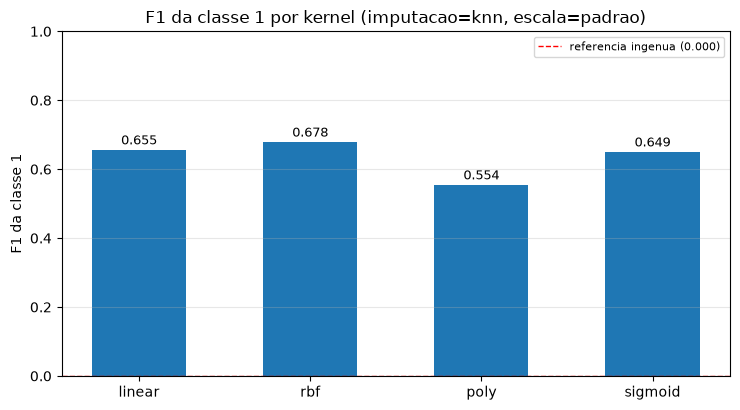

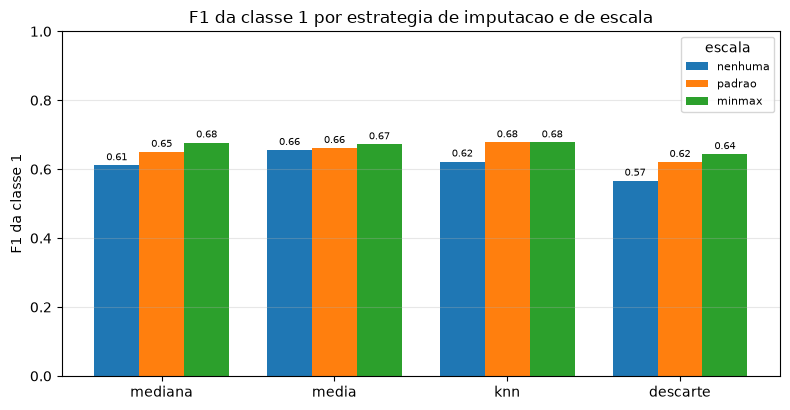

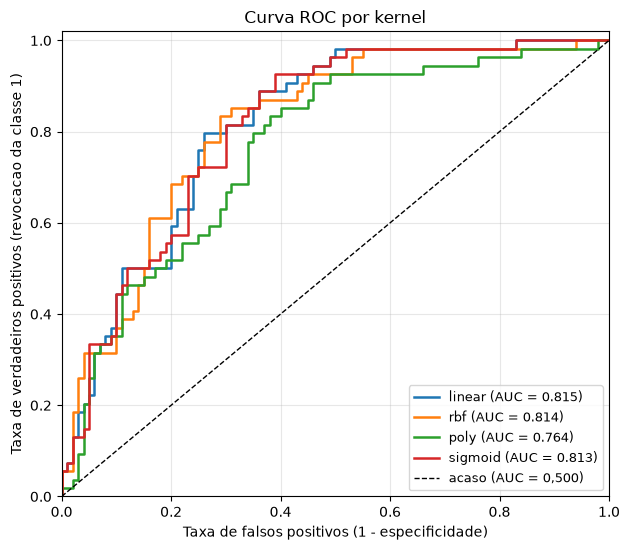

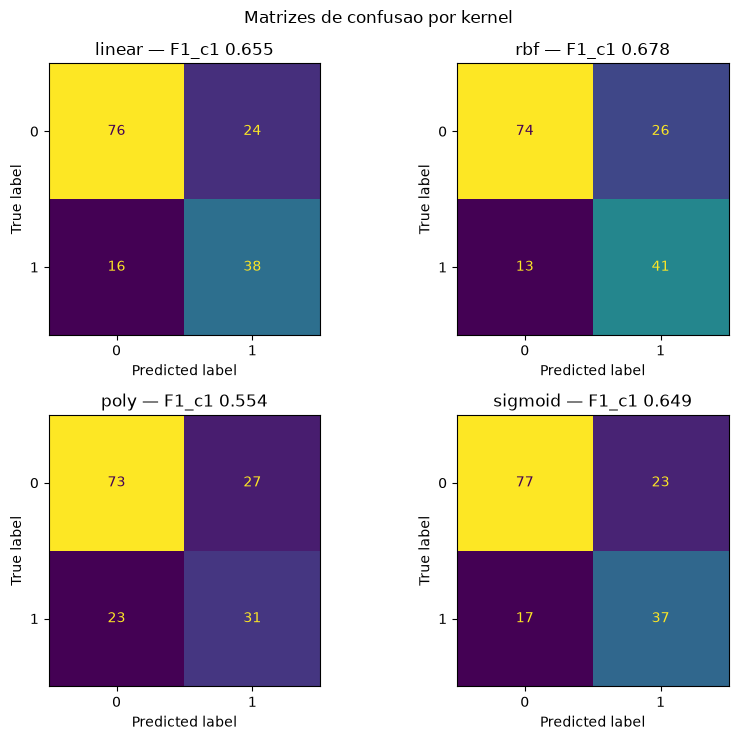

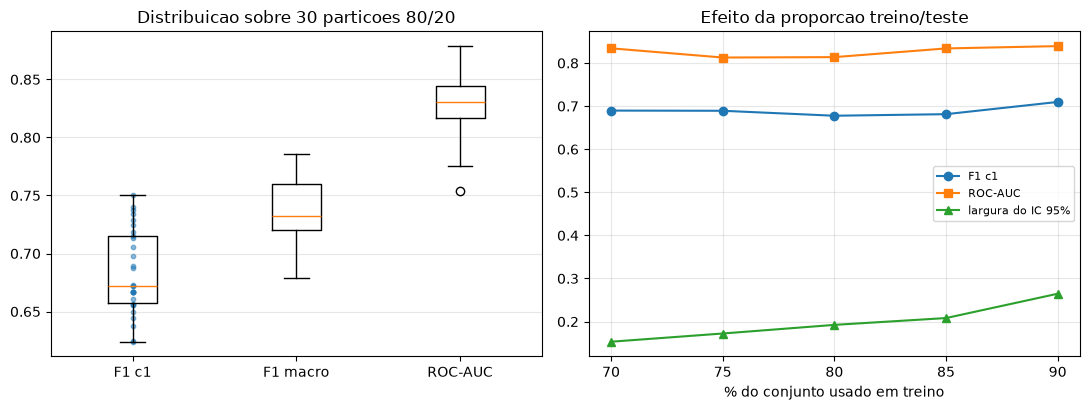

Resumo da variabilidade entre particoes (F1 da classe 1): media 0.6834 | desvio 0.0358 | amplitude 0.6240 a 0.7500


In [12]:
# 1) F1 da classe 1 por kernel
fig, ax = plt.subplots(figsize=(7.5, 4.2))
b = ax.bar(por_kernel['Kernel'], por_kernel['F1_c1'], color='tab:blue', width=0.55)
ax.bar_label(b, fmt='%.3f', fontsize=9, padding=2)
ax.axhline(float(baseline['F1_c1'].iloc[0]), color='red', linestyle='--', linewidth=1,
           label=f"referencia ingenua ({float(baseline['F1_c1'].iloc[0]):.3f})")
ax.set_ylabel('F1 da classe 1'); ax.set_ylim(0, 1)
ax.set_title(f'F1 da classe 1 por kernel (imputacao={REF_IMP}, escala={REF_ESC})')
ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
fig.tight_layout(); salva_fig(fig, 'f1_por_kernel.png'); plt.show()

# 2) pre-processamento: imputacao x escala
piv = comparacao.pivot(index='Imputacao', columns='Escala', values='F1_c1')
piv = piv.reindex(index=IMPUTACOES, columns=ESCALAS)
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(IMPUTACOES)); larg = 0.26
for i, e in enumerate(ESCALAS):
    bb = ax.bar(x + (i - 1) * larg, piv[e].values, larg, label=e)
    ax.bar_label(bb, fmt='%.2f', fontsize=7, padding=2)
ax.set_xticks(x); ax.set_xticklabels(IMPUTACOES)
ax.set_ylabel('F1 da classe 1'); ax.set_ylim(0, 1)
ax.set_title('F1 da classe 1 por estrategia de imputacao e de escala')
ax.legend(title='escala', fontsize=8); ax.grid(axis='y', alpha=0.3)
fig.tight_layout(); salva_fig(fig, 'preprocessamento.png'); plt.show()

# 3) curva ROC por kernel
fig, ax = plt.subplots(figsize=(6.4, 5.6))
for k, (pipe_k, score_k) in modelos_k.items():
    if score_k is None:
        continue
    fpr, tpr, _ = roc_curve(y_ref[ite_ref], score_k)
    auc = roc_auc_score(y_ref[ite_ref], score_k)
    ax.plot(fpr, tpr, linewidth=1.8, label=f'{k} (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='acaso (AUC = 0,500)')
ax.set_xlabel('Taxa de falsos positivos (1 - especificidade)')
ax.set_ylabel('Taxa de verdadeiros positivos (revocacao da classe 1)')
ax.set_title('Curva ROC por kernel')
ax.legend(loc='lower right', fontsize=9); ax.grid(alpha=0.3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
fig.tight_layout(); salva_fig(fig, 'curva_roc_por_kernel.png'); plt.show()

# 4) matrizes de confusao por kernel
fig, eixos = plt.subplots(2, 2, figsize=(8.5, 7.5))
for ax, k in zip(eixos.ravel(), KERNELS):
    if k not in modelos_k:
        ax.axis('off'); continue
    pred = modelos_k[k][0].predict(X_ref[ite_ref])
    ConfusionMatrixDisplay.from_predictions(y_ref[ite_ref], pred, ax=ax, colorbar=False)
    f1 = float(por_kernel.set_index('Kernel').loc[k, 'F1_c1'])
    ax.set_title(f'{k} — F1_c1 {f1:.3f}')
fig.suptitle('Matrizes de confusao por kernel', fontsize=12)
fig.tight_layout(); salva_fig(fig, 'matrizes_confusao_kernels.png'); plt.show()

# 5) distribuicao das metricas sobre as particoes repetidas
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
dados_box = [repeticoes['F1_c1'], repeticoes['F1_macro'], repeticoes['ROC_AUC']]
try:
    eixos[0].boxplot(dados_box, tick_labels=['F1 c1', 'F1 macro', 'ROC-AUC'])
except TypeError:
    eixos[0].boxplot(dados_box, labels=['F1 c1', 'F1 macro', 'ROC-AUC'])
eixos[0].scatter(np.ones(len(repeticoes)) * 1, repeticoes['F1_c1'], s=10, alpha=0.5,
                 color='tab:blue')
eixos[0].set_title(f'Distribuicao sobre {len(repeticoes)} particoes 80/20')
eixos[0].grid(axis='y', alpha=0.3)
eixos[1].plot(proporcao['Treino_%'], proporcao['F1_c1'], marker='o', label='F1 c1')
eixos[1].plot(proporcao['Treino_%'], proporcao['ROC_AUC'], marker='s', label='ROC-AUC')
eixos[1].plot(proporcao['Treino_%'], proporcao['Largura_IC95'], marker='^',
              label='largura do IC 95%')
eixos[1].set_xlabel('% do conjunto usado em treino'); eixos[1].set_xticks(proporcao['Treino_%'])
eixos[1].set_title('Efeito da proporcao treino/teste')
eixos[1].legend(fontsize=8); eixos[1].grid(alpha=0.3)
fig.tight_layout(); salva_fig(fig, 'sensibilidade_particao.png'); plt.show()

print('Resumo da variabilidade entre particoes (F1 da classe 1): '
      f"media {repeticoes['F1_c1'].mean():.4f} | desvio {repeticoes['F1_c1'].std():.4f} | "
      f"amplitude {repeticoes['F1_c1'].min():.4f} a {repeticoes['F1_c1'].max():.4f}")

## Exportar resultados

Salva as tabelas, as figuras e os melhores hiperparâmetros; empacota tudo em um ZIP e registra como artefato no MLflow.

In [13]:
parametros = {
    'cenario_referencia': {'imputacao': str(REF_IMP), 'escala': str(REF_ESC),
                           **{k: str(v) for k, v in PARAMS_REF.items()}},
    'por_kernel': {r['Kernel']: r['Parametros'] for _, r in por_kernel.iterrows()},
    'com_engenharia': {k.replace('modelo__', ''): str(v)
                       for k, v in busca_eng['com_engenharia'].best_params_.items()},
    'protocolo': {'fracao_teste': TESTE_FRACAO, 'semente': SEED,
                  'cv': f'RepeatedStratifiedKFold({N_SPLITS}x{N_REPEATS})',
                  'n_combinacoes': N_COMBINACOES, 'modo': MODO},
}
with open(PASTA_EXECUCAO / 'melhores_hiperparametros_svm.json', 'w', encoding='utf-8') as f:
    json.dump(parametros, f, ensure_ascii=False, indent=2)

arquivos = sorted(str(p) for p in PASTA_EXECUCAO.glob('*')
                  if p.suffix in {'.csv', '.png', '.json'})
zip_path = PASTA_EXECUCAO / 'resultados_svm.zip'
with zipfile.ZipFile(zip_path, 'w') as z:
    for a in arquivos:
        z.write(a, arcname=Path(a).name)

with mlflow.start_run(run_name='relatorio_artefatos'):
    for a in arquivos + [str(zip_path)]:
        mlflow.log_artifact(a)
    mlflow.log_param('pasta_execucao', str(PASTA_EXECUCAO))
    mlflow.log_param('modo', MODO)
    mlflow.log_metric('n_arquivos', len(arquivos))

print('Pasta da execucao:', PASTA_EXECUCAO)
print('Arquivos:', ', '.join(Path(a).name for a in arquivos))

Pasta da execucao: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/docs/svm/resultados/execucao_20261116_100225
Arquivos: baseline.csv, comparacao_kernels.csv, comparacao_preprocessamento.csv, curva_roc_por_kernel.png, distribuicao_por_classe.png, efeito_class_weight.csv, efeito_escala.csv, efeito_imputacao.csv, engenharia_ablacao_individual.csv, engenharia_neutralizacao.csv, engenharia_retreino.csv, esquema_validacao.csv, f1_por_kernel.png, limpeza.csv, mapa_correlacao.png, matrizes_confusao_kernels.png, melhores_hiperparametros_svm.json, particao_estratificacao.csv, particao_estratificacao_resumo.csv, particao_proporcao.csv, particao_repeticoes.csv, particao_repeticoes_resumo.csv, particao_reselecao.csv, preprocessamento.png, sensibilidade_particao.png, vies_casos_completos.csv, zeros_por_coluna.csv


## Consultar e comparar no MLflow

In [14]:
print('Tracking URI:', mlflow.get_tracking_uri())
print('Experimento:', EXPERIMENTO)

runs = mlflow.search_runs(experiment_names=[EXPERIMENTO])
print('Runs registradas:', len(runs))
runs.to_csv(PASTA_DOCS / 'mlflow_runs_svm.csv', index=False)

colunas = [c for c in ['tags.mlflow.runName', 'metrics.f1_cv', 'metrics.F1_c1',
                       'metrics.F1_macro', 'metrics.ROC_AUC', 'metrics.FN']
           if c in runs.columns]
if 'tags.mlflow.runName' in runs.columns:
    principais = runs[runs['tags.mlflow.runName'].str.startswith('svm_', na=False)]
    display(principais[colunas].sort_values('metrics.F1_c1', ascending=False)
            .round(4).reset_index(drop=True))

print('\nPara abrir a interface do MLflow, no terminal, na raiz do projeto:')
print('  mlflow ui --backend-store-uri sqlite:///mlflow.db')
print('Depois acesse http://127.0.0.1:5000 e selecione o experimento', EXPERIMENTO)

Tracking URI: sqlite:////Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/mlflow.db
Experimento: pima_svm
Runs registradas: 177


,tags.mlflow.runName,metrics.f1_cv,metrics.F1_c1,metrics.F1_macro,metrics.ROC_AUC,metrics.FN
0,svm_knn_padrao,0.6965,0.6777,0.7346,0.8137,13.0
1,svm_knn_padrao,0.6965,0.6777,0.7346,0.8137,13.0
2,svm_knn_padrao,0.6965,0.6777,0.7346,0.8137,13.0
3,svm_knn_minmax,0.6929,0.6774,0.7300,0.8070,12.0
4,svm_knn_minmax,0.6929,0.6774,0.7300,0.8070,12.0
5,svm_knn_minmax,0.6929,0.6774,0.7300,0.8070,12.0
6,svm_mediana_minmax,0.6886,0.6772,0.7253,0.8096,11.0
7,svm_mediana_minmax,0.6886,0.6772,0.7253,0.8096,11.0
8,svm_mediana_minmax,0.6886,0.6772,0.7253,0.8096,11.0
9,svm_media_minmax,0.6942,0.6719,0.7193,0.8096,11.0



Para abrir a interface do MLflow, no terminal, na raiz do projeto:
  mlflow ui --backend-store-uri sqlite:///mlflow.db
Depois acesse http://127.0.0.1:5000 e selecione o experimento pima_svm
